In [3]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import datetime as dt
import numpy as np

In [4]:
df=pd.read_csv('covid_19_india.csv',parse_dates=['Date'],dayfirst=True)

/tmp/ipykernel_252/689802896.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df=pd.read_csv('covid_19_india.csv',parse_dates=['Date'],dayfirst=True)


In [8]:
df.head()

,date,state,cured,deaths,confirmed
0,2020-01-30,Kerala,0,0,1
1,2020-01-31,Kerala,0,0,1
2,2020-02-01,Kerala,0,0,2
3,2020-02-02,Kerala,0,0,3
4,2020-02-03,Kerala,0,0,3


In [7]:
df=df[["Date",'State/UnionTerritory','Cured','Deaths','Confirmed']]
df.columns=['date','state','cured','deaths','confirmed']

In [9]:
df.head()

,date,state,cured,deaths,confirmed
0,2020-01-30,Kerala,0,0,1
1,2020-01-31,Kerala,0,0,1
2,2020-02-01,Kerala,0,0,2
3,2020-02-02,Kerala,0,0,3
4,2020-02-03,Kerala,0,0,3


In [20]:
today = df[df['date'] == '2020-04-23']

confirmed cases

In [10]:
max_confirmed_cases=df.sort_values(by='confirmed',ascending=False)

In [11]:
max_confirmed_cases.head()

,date,state,cured,deaths,confirmed
1240,2020-04-23,Maharashtra,789,269,5652
1208,2020-04-22,Maharashtra,722,251,5221
1175,2020-04-21,Maharashtra,572,232,4669
1142,2020-04-20,Maharashtra,507,223,4203
1109,2020-04-19,Maharashtra,365,211,3651


In [15]:
top_state_confirmed=max_confirmed_cases[0:5].head()

In [16]:
top_state_confirmed

,date,state,cured,deaths,confirmed
1240,2020-04-23,Maharashtra,789,269,5652
1208,2020-04-22,Maharashtra,722,251,5221
1175,2020-04-21,Maharashtra,572,232,4669
1142,2020-04-20,Maharashtra,507,223,4203
1109,2020-04-19,Maharashtra,365,211,3651


<Axes: xlabel='state', ylabel='confirmed'>

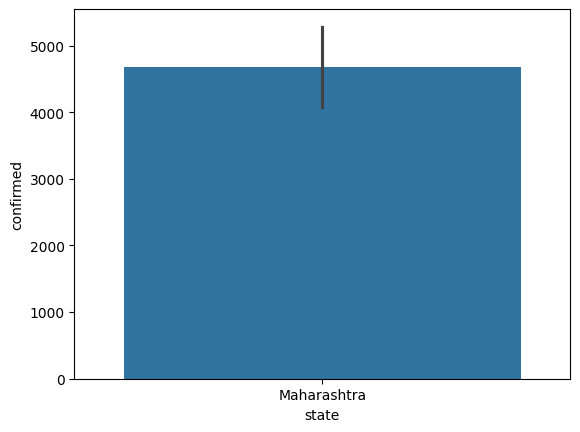

In [18]:
sns.barplot(x='state', y='confirmed', data=top_state_confirmed, hue='state')

In [21]:
max_death_cases=today.sort_values(by='deaths',ascending=False)

In [22]:
max_death_cases.head()

,date,state,cured,deaths,confirmed
1240,2020-04-23,Maharashtra,789,269,5652
1231,2020-04-23,Gujarat,179,103,2407
1239,2020-04-23,Madhya Pradesh,148,81,1695
1229,2020-04-23,Delhi,724,48,2248
1223,2020-04-23,Andhra Pradesh,141,27,895


In [23]:
top_state_death=max_death_cases[0:5].head()

In [24]:
top_state_death

,date,state,cured,deaths,confirmed
1240,2020-04-23,Maharashtra,789,269,5652
1231,2020-04-23,Gujarat,179,103,2407
1239,2020-04-23,Madhya Pradesh,148,81,1695
1229,2020-04-23,Delhi,724,48,2248
1223,2020-04-23,Andhra Pradesh,141,27,895


<Axes: xlabel='state', ylabel='deaths'>

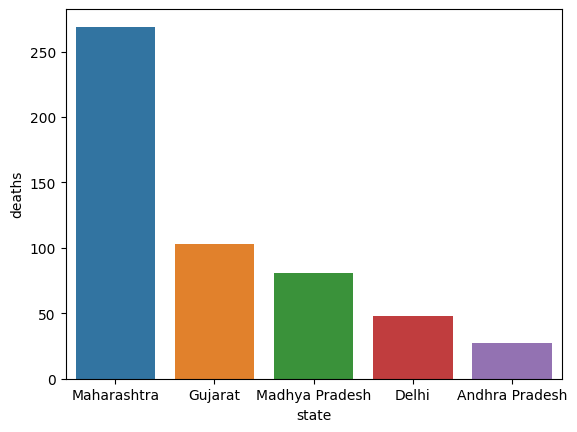

In [25]:
sns.barplot(x='state',y='deaths',data=top_state_death,hue='state')

Linear Regression

In [26]:
maha=df[df.state=="Maharashtra"]

In [27]:
maha

,date,state,cured,deaths,confirmed
76,2020-03-09,Maharashtra,0,0,2
91,2020-03-10,Maharashtra,0,0,5
97,2020-03-11,Maharashtra,0,0,2
120,2020-03-12,Maharashtra,0,0,11
133,2020-03-13,Maharashtra,0,0,14
146,2020-03-14,Maharashtra,0,0,14
153,2020-03-15,Maharashtra,0,0,32
167,2020-03-16,Maharashtra,0,0,32
182,2020-03-17,Maharashtra,0,1,39
197,2020-03-18,Maharashtra,0,1,42


x=>date,y=>conformed case

<Axes: xlabel='date', ylabel='confirmed'>

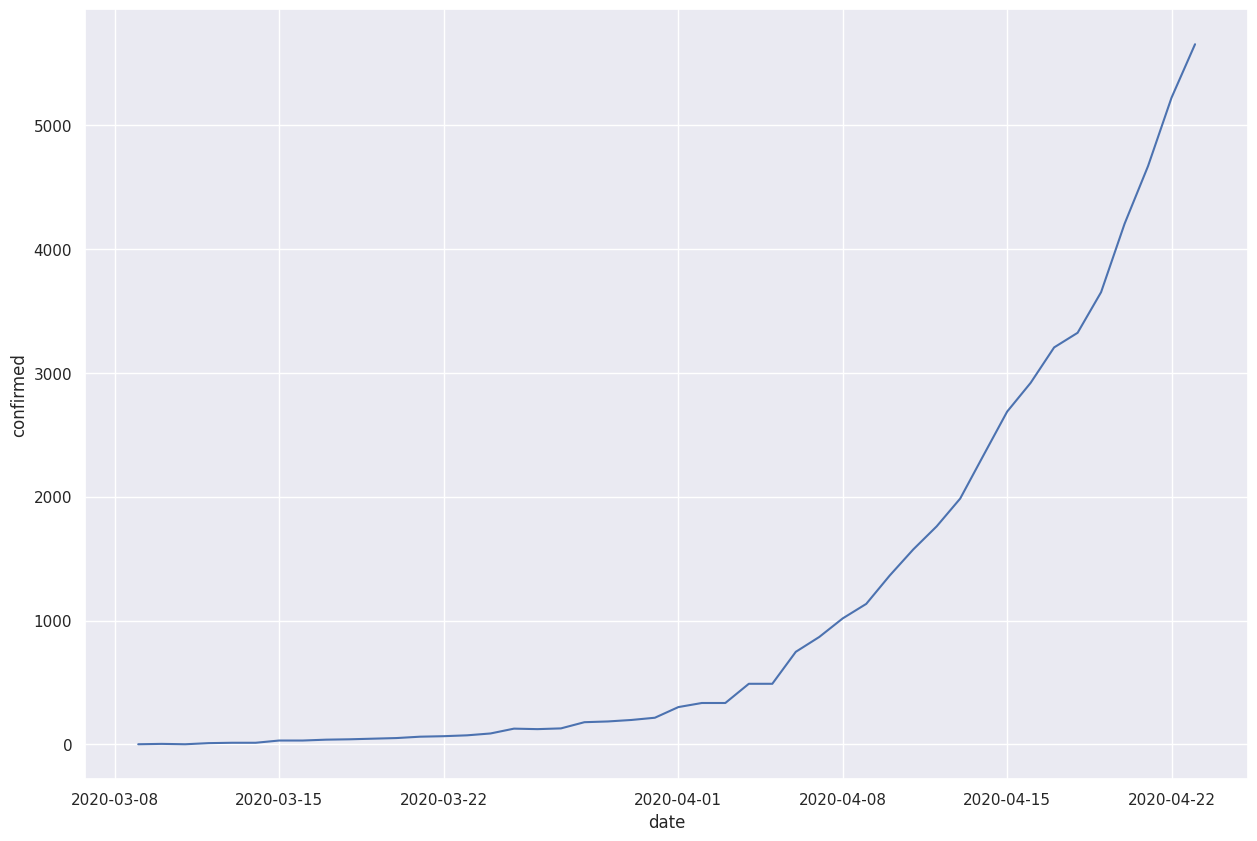

In [28]:
sns.set(rc={'figure.figsize':(15,10)})
sns.lineplot(x='date',y='confirmed',data=maha)

extract data fr gujrat

In [32]:
Guj=df[df.state=="Gujarat"]

<Axes: xlabel='date', ylabel='confirmed'>

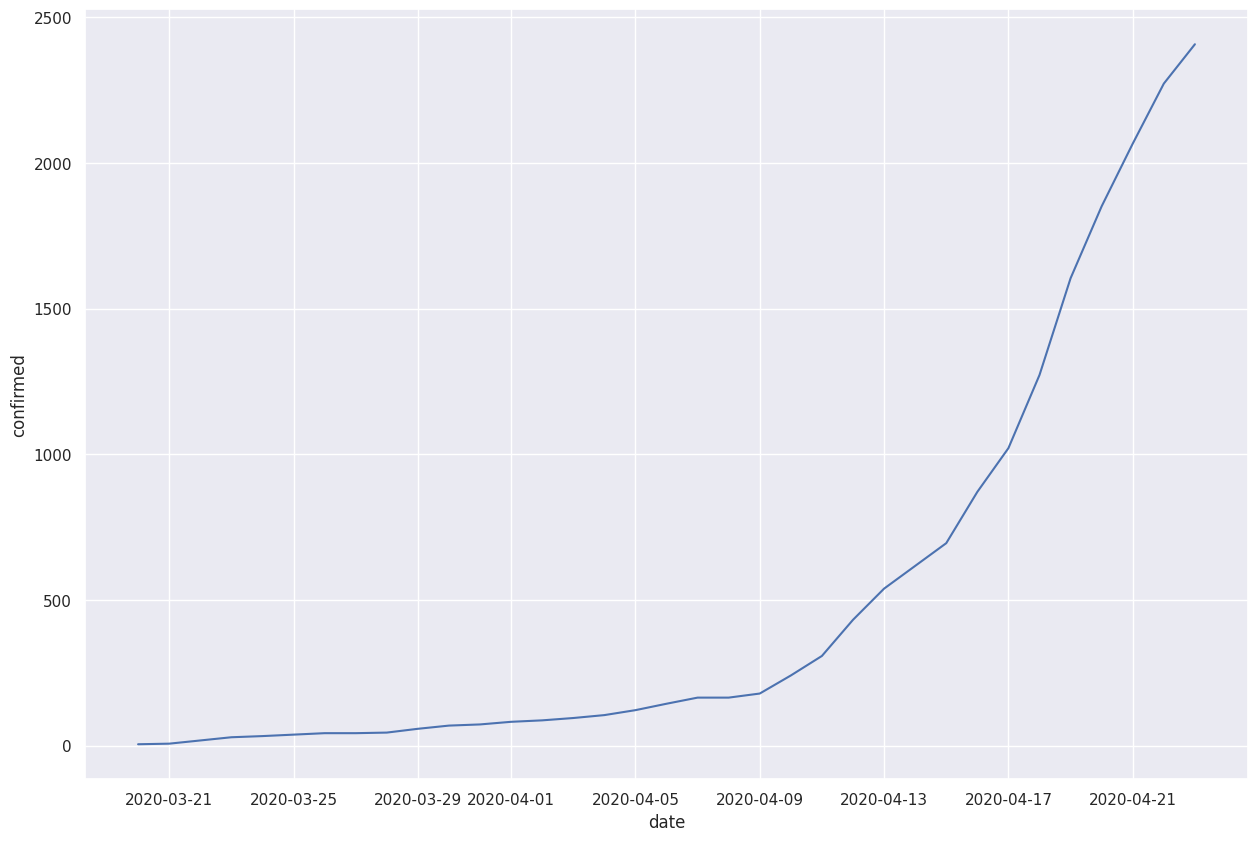

In [33]:
sns.set(rc={'figure.figsize':(15,10)})
sns.lineplot(x='date',y='confirmed',data=Guj)

<Axes: xlabel='date', ylabel='deaths'>

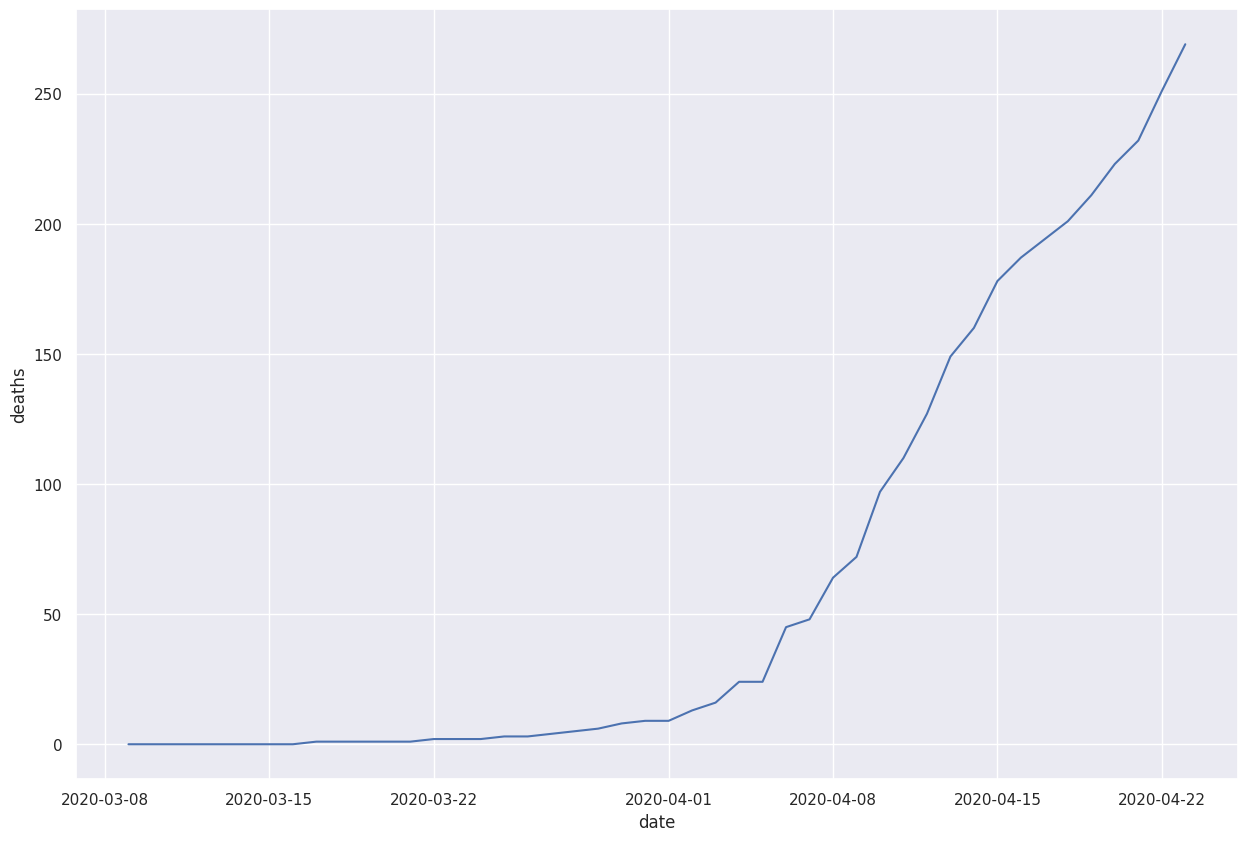

In [35]:
sns.set(rc={'figure.figsize':(15,10)})
sns.lineplot(x='date',y='deaths',data=maha)

<Axes: xlabel='date', ylabel='deaths'>

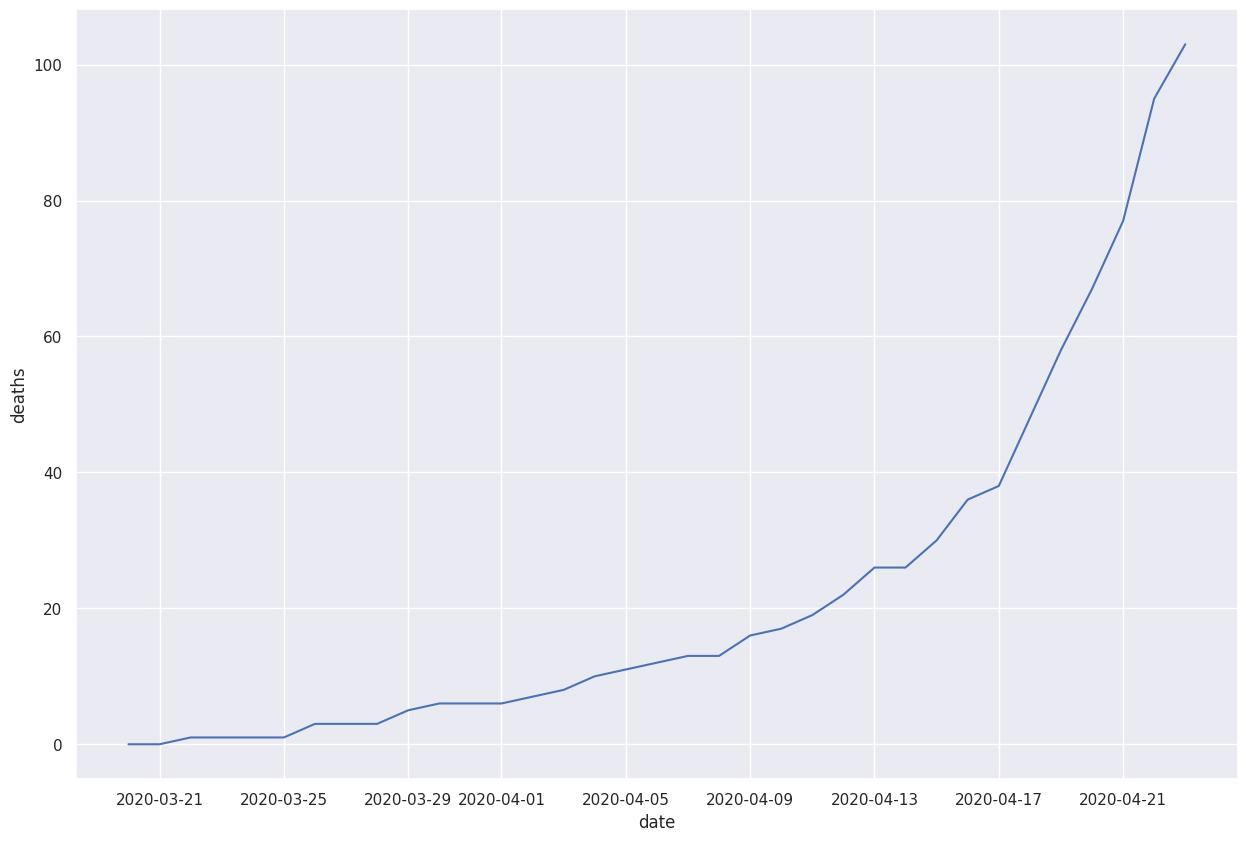

In [37]:
sns.set(rc={'figure.figsize':(15,10)})
sns.lineplot(x='date',y='deaths',data=Guj)

Linear Regression Apply now

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [57]:
x=maha['date']
y=maha['confirmed']

In [61]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=0)

In [62]:
lr=LinearRegression

In [63]:
y_train

,confirmed
1240,5652
407,130
326,89
666,490
350,128
1109,3651
1076,3323
182,39
280,67
146,14


In [64]:
lr_instance.fit(np.array(x_train).reshape(-1, 1), np.array(y_train).reshape(-1, 1))

LinearRegression()

In [65]:
target_date=pd.to_datetime('2020-04-20').toordinal

In [74]:
# 1. Properly instantiate the LinearRegression model
lr = LinearRegression()

# 2. Fit the model on our correct training data (ordinals vs. confirmed cases)
lr.fit(np.array(x_train).reshape(-1, 1), np.array(y_train).reshape(-1, 1))

# 3. Predict the confirmed cases for the target date
target_ordinal = pd.to_datetime('2020-04-20').toordinal()
lr.predict(np.array([[target_ordinal]]).reshape(-1, 1))

array([[-1153428.56028379]])

For Gujrat

In [66]:
x=Guj['date']
y=Guj['confirmed']

In [67]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=0)

In [68]:
lr=LinearRegression

In [76]:
lr.fit(np.array(x_train).reshape(-1, 1), np.array(y_train).reshape(-1, 1))

LinearRegression()

In [77]:
target_date=pd.to_datetime('2020-04-20').toordinal

In [79]:
target_ordinal = pd.to_datetime('2020-04-20').toordinal()
lr.predict(np.array([[target_ordinal]]))

array([[-1153428.56028379]])